<a href="https://colab.research.google.com/github/Clinton1029/Auto-MPG-Prediction-/blob/main/group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## QUESTION 1: Applied Analytics Process and Problem Formulation

### 1(a) Stakeholder, Decision and Analytical Question

**Stakeholder:**

The main stakeholder is an automobile manufacturer or car
dealer interested in understanding and estimating the fuel
efficiency of different vehicles.

**Decision to be Supported:**

The analysis will help automobile manufacturers and car
dealers understand how vehicle characteristics influence
fuel efficiency. It can support decisions when designing,
selecting or recommending vehicles with better fuel economy.

**Analytical Question:**

To what extent can vehicle characteristics such as
cylinders, displacement, horsepower, weight, acceleration,
model year and origin be used to predict a vehicle's fuel
efficiency (miles per gallon)?

### 1(b) Target Variable, Predictors and Learning Task

**Response (Target) Variable:**

The target variable is `mpg` (miles per gallon), which
measures the fuel efficiency of a vehicle.

**Predictor Variables:**

The proposed predictors are:

1. Cylinders – Number of engine cylinders.
2. Displacement – Engine displacement in cubic inches.
3. Horsepower – Engine power output.
4. Weight – Total vehicle weight in pounds.
5. Acceleration – Vehicle acceleration time in seconds.
6. Model year – Year of vehicle manufacture.
7. Origin – Geographical origin of the vehicle.

The `car name` variable will be excluded because it is
an identifier containing vehicle model names rather than
a direct numerical vehicle specification.

**Learning Task:**

The problem is a supervised machine learning regression
task because the objective is to predict a continuous
numerical value (mpg) using vehicle characteristics.

**Measurable Performance Criterion:**

The model will be evaluated using Mean Absolute Error
(MAE), Root Mean Squared Error (RMSE) and R-squared (R²).

The model will be considered practically useful if it
achieves a lower test RMSE than the baseline model that
predicts the mean MPG of the training data, together with
a reasonably high test R-squared value.

### 1(c) Six Stages of the Applied Analytics Process

The Auto MPG prediction problem follows six stages of the
Applied Analytics Process as described below.

**1. Problem/Business Understanding**

Activity:
Identify the need to understand and predict vehicle fuel
efficiency using vehicle characteristics.

Expected Output:
A clearly defined analytical problem, stakeholder and
objective of predicting miles per gallon (mpg).

**2. Data Understanding**

Activity:
Load and examine the Auto MPG dataset to understand its
structure, variables, data types, distributions and data
quality issues.

Expected Output:
An understanding of the dataset, including its variables,
missing values, relationships and possible data quality
problems.

**3. Data Preparation**

Activity:
Clean the dataset by handling missing horsepower values,
checking duplicates, correcting data types and selecting
appropriate predictors. Treat origin as categorical and
exclude car name from the introductory regression model.

Expected Output:
A clean and appropriately prepared dataset suitable for
exploratory analysis and regression modelling.

**4. Modelling**

Activity:
Develop a multiple linear regression model using selected
vehicle characteristics to predict MPG.

Expected Output:
A fitted regression model that estimates vehicle fuel
efficiency from the selected predictors.

**5. Evaluation**

Activity:
Evaluate model performance using test data and metrics
such as MAE, RMSE and R-squared. Compare the model against
a baseline prediction.

Expected Output:
Performance results showing the accuracy and limitations
of the regression model.

**6. Communication/Deployment**

Activity:
Present the findings, model performance, visualizations
and recommendations to automobile manufacturers or car
dealers. The model can be used to estimate the fuel
efficiency of vehicles with available specifications.

Expected Output:
A clear analytical report and a usable prediction model
that supports vehicle selection and design decisions.

### 1(d) Limitation or Risk

One limitation is that the Auto MPG dataset contains
historical vehicle information.
Consequently, the model may not accurately predict the
fuel efficiency of modern vehicles because vehicle
technology and engine designs have changed over time.

If model evaluation reveals high prediction errors,
the analyst may return to the data understanding stage
to investigate the dataset or to the modelling stage
to improve predictor selection and model performance.

## QUESTION 2: Importation, Inspection and Data Dictionary

### 2(a) Importation of Python Libraries

The following Python libraries are imported to support
data manipulation, statistical analysis, visualization
and regression modelling in the Auto MPG project.

In [1]:
# Import os to interact with the operating system and manage file paths
import os

# Import pandas for loading, organizing and manipulating datasets
import pandas as pd

# Import numpy for numerical computations and array operations
import numpy as np

# Import matplotlib.pyplot for creating graphs and visualizations
import matplotlib.pyplot as plt

# Import seaborn for statistical data visualization
import seaborn as sns

# Import train_test_split to divide the dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Import ColumnTransformer to apply different preprocessing
# operations to numerical and categorical columns
from sklearn.compose import ColumnTransformer

In [2]:
# Set Pandas to display floating-point numbers to three decimal places
# This improves the readability of numerical outputs in tables
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Set Seaborn's visualization theme to whitegrid
# This adds a white background with grid lines to improve plot readability
sns.set_theme(style="whitegrid")

### 2.3 Importing the data

In [ ]:
file = r"C:\Users\blaqc\Downloads\auto-mpg.csv"
if os.path.exists(file):
    print("file found!")
    df = pd.read_csv(file)
else:
    print("file not found!")


file found!


### 2.3.1 Data inspection

In [ ]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [ ]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.000,4,140.000,86.000,2790,15.600,82,1,ford mustang gl
394,44.000,4,97.000,52.000,2130,24.600,82,2,vw pickup
395,32.000,4,135.000,84.000,2295,11.600,82,1,dodge rampage
396,28.000,4,120.000,79.000,2625,18.600,82,1,ford ranger
397,31.000,4,119.000,82.000,2720,19.400,82,1,chevy s-10


In [ ]:
df.sample(10, random_state=42)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
198,33.000,4,91.000,53.000,1795,17.400,76,3,honda civic
396,28.000,4,120.000,79.000,2625,18.600,82,1,ford ranger
33,19.000,6,232.000,100.000,2634,13.000,71,1,amc gremlin
208,13.000,8,318.000,150.000,3940,13.200,76,1,plymouth volare premier v8
93,14.000,8,318.000,150.000,4237,14.500,73,1,plymouth fury gran sedan
84,27.000,4,97.000,88.000,2100,16.500,72,3,toyota corolla 1600 (sw)
373,24.000,4,140.000,92.000,2865,16.400,82,1,ford fairmont futura
94,13.000,8,440.000,215.000,4735,11.000,73,1,chrysler new yorker brougham
222,17.000,8,260.000,110.000,4060,19.000,77,1,oldsmobile cutlass supreme
126,21.000,6,200.000,NaN,2875,17.000,74,1,ford maverick


In [ ]:
df.columns.tolist()

['mpg',
 'cylinders',
 'displacement',
 'horsepower',
 'weight',
 'acceleration',
 'model year',
 'origin',
 'car name']

In [ ]:
df.shape

(398, 9)

In [ ]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model year        int64
origin            int64
car name            str
dtype: object

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(4), int64(4), str(1)
memory usage: 34.4 KB


In [ ]:
df.nunique().sort_values()

origin            3
cylinders         5
model year       13
displacement     82
horsepower       94
acceleration     95
mpg             129
car name        305
weight          351
dtype: int64

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mpg,398.000,23.515,7.816,9.000,17.500,23.000,29.000,46.600
cylinders,398.000,5.455,1.701,3.000,4.000,4.000,8.000,8.000
displacement,398.000,193.426,104.270,68.000,104.250,148.500,262.000,455.000
horsepower,392.000,104.469,38.491,46.000,75.000,93.500,126.000,230.000
weight,398.000,"2,970.425",846.842,"1,613.000","2,223.750","2,803.500","3,608.000","5,140.000"
acceleration,398.000,15.568,2.758,8.000,13.825,15.500,17.175,24.800
model year,398.000,76.010,3.698,70.000,73.000,76.000,79.000,82.000
origin,398.000,1.573,0.802,1.000,1.000,1.000,2.000,3.000


* if median(50%) is  < mean this shows huge values are pulling the mean up

* if median(50%) is > mean this shows low values are pulling mean down which implies  left-skewness

* if median is approximately close to mean or equal to implies a symetrical data

* std shows how values are spread from the mean

### Question 3

In [ ]:
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
missing = (df.isna().sum() / len(df)) * 100
missing

mpg            0.000
cylinders      0.000
displacement   0.000
horsepower     1.508
weight         0.000
acceleration   0.000
model year     0.000
origin         0.000
car name       0.000
dtype: float64

In [ ]:
print(df.loc[df["horsepower"].isna(),  ["car name", "horsepower"]])

                 car name  horsepower
32             ford pinto         NaN
126         ford maverick         NaN
330  renault lecar deluxe         NaN
336    ford mustang cobra         NaN
354           renault 18i         NaN
374        amc concord dl         NaN


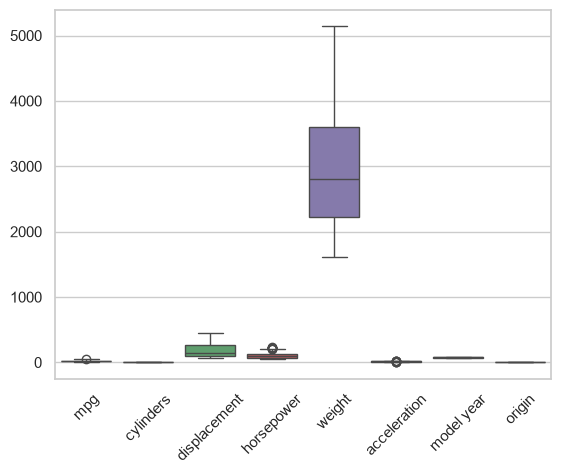

In [ ]:
sns.boxplot(data=df)
plt.xticks(rotation=45)
plt.show()

In [ ]:
X = df.drop("mpg", axis=1)
y = df["mpg"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [ ]:
X_train.shape

(298, 8)

In [ ]:
y_train.shape

(298,)

In [ ]:
X_tra

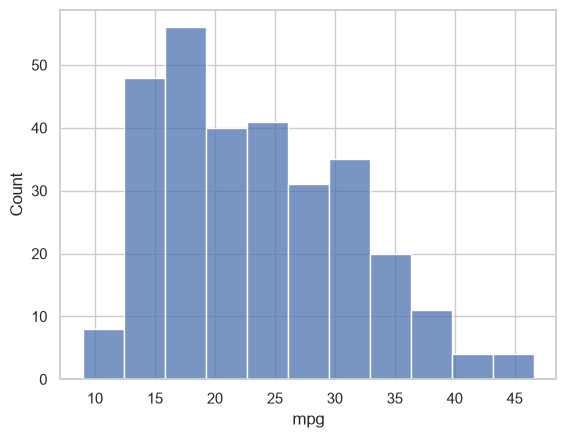

In [ ]:
sns.histplot(data=X_train, x=y_train)
plt.show()

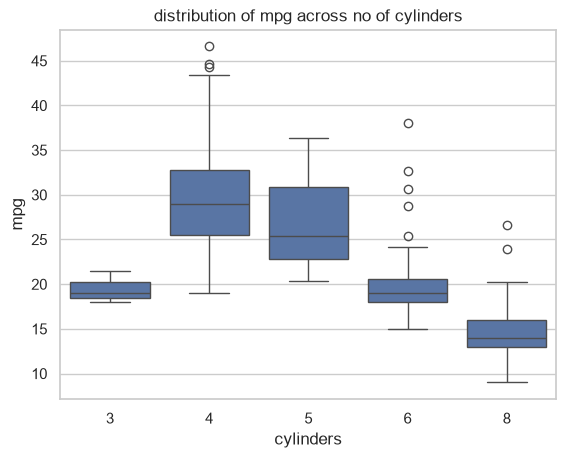

In [ ]:
sns.boxplot(data=X_train, x="cylinders", y=y_train)
plt.title("distribution of mpg across no of cylinders")
plt.show()

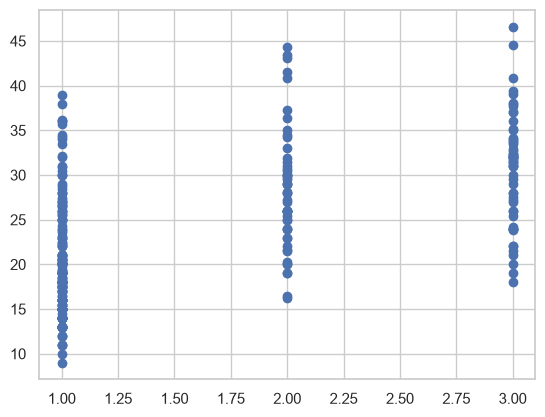

In [ ]:
plt.scatter(X_train["origin"], y_train)
plt.show()

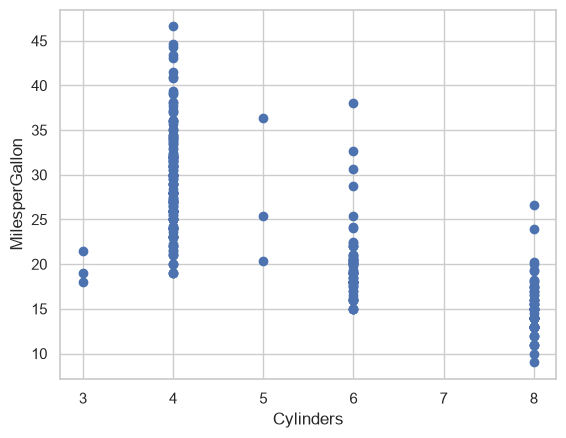

In [ ]:
plt.scatter(X_train["cylinders"], y_train)
plt.xlabel("Cylinders")
plt.ylabel("MilesperGallon")
plt.show()

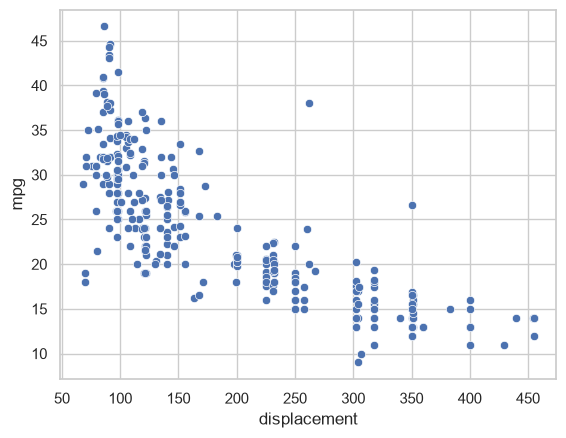

In [ ]:
sns.scatterplot(data=X_train, x=X_train["displacement"], y=y_train)
plt.show()

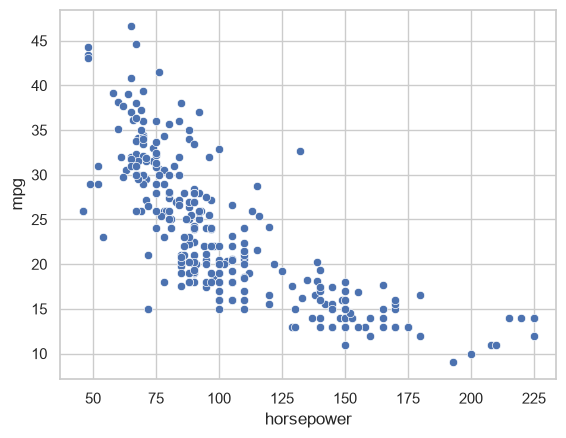

In [ ]:
sns.scatterplot(data=X_train, x=X_train["horsepower"], y=y_train)
plt.show()

<Axes: xlabel='horsepower', ylabel='mpg'>

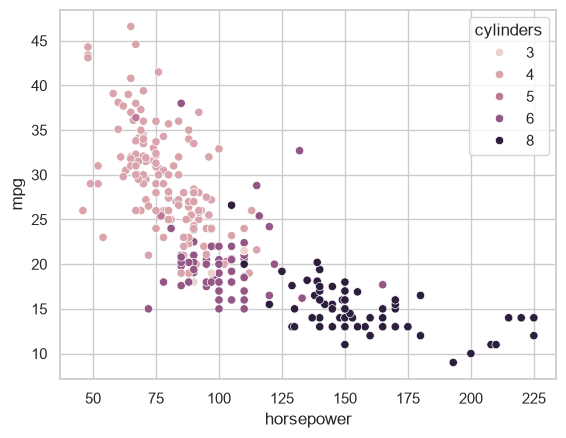

In [ ]:
sns.scatterplot(data=X_train, x=X_train["horsepower"], y=y_train, hue=X_train["cylinders"])

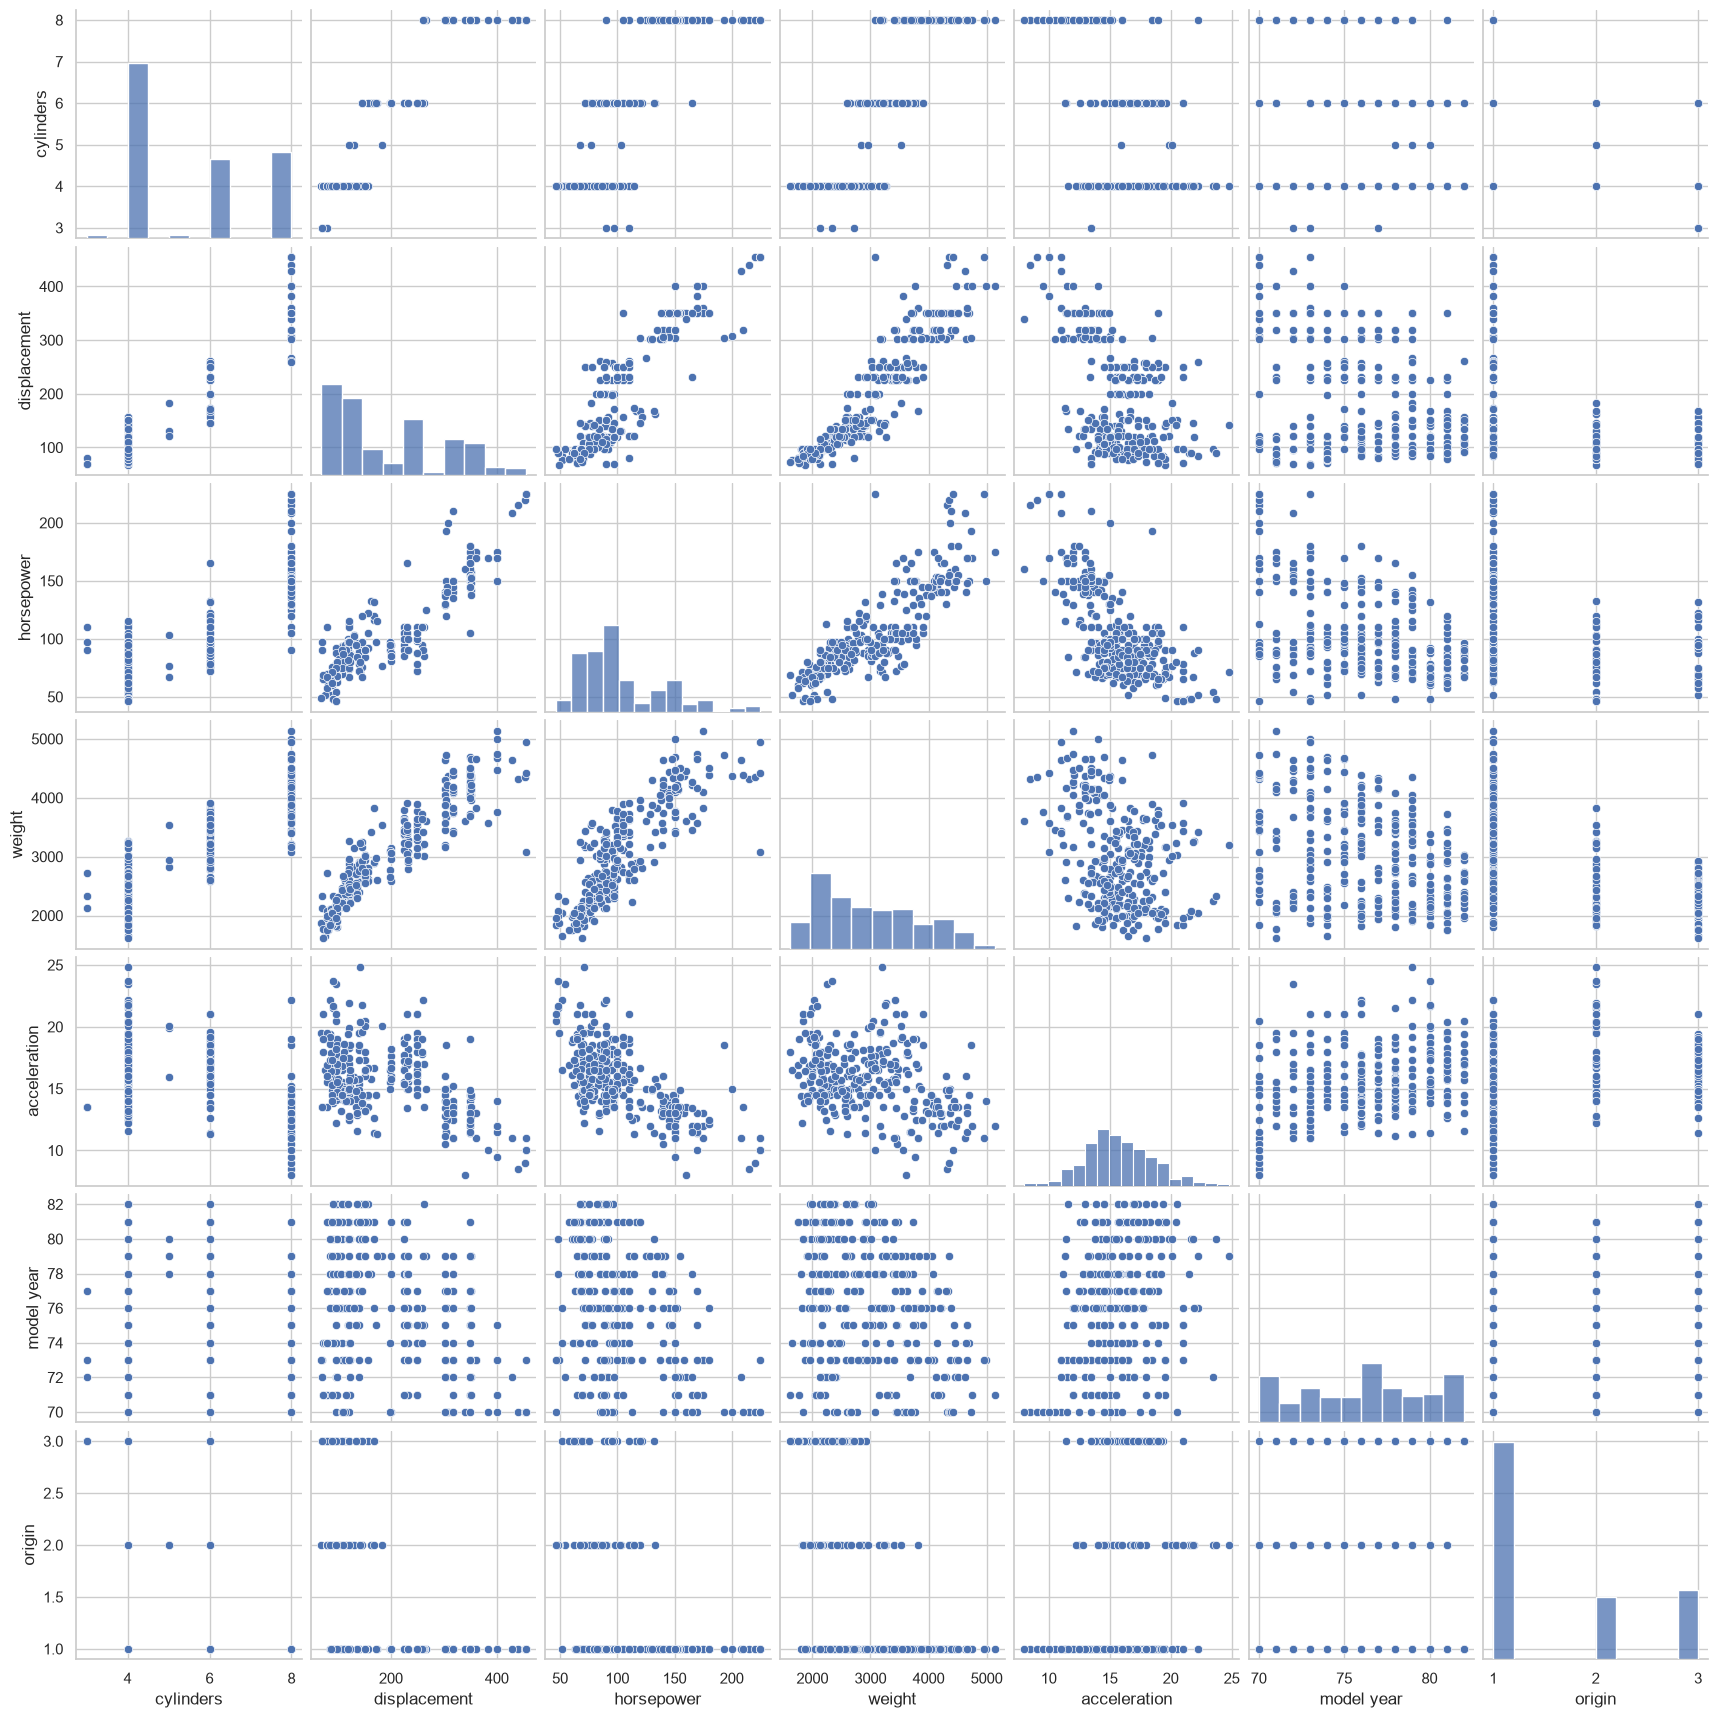

In [ ]:
sns.pairplot(data=X_train)
plt.show()

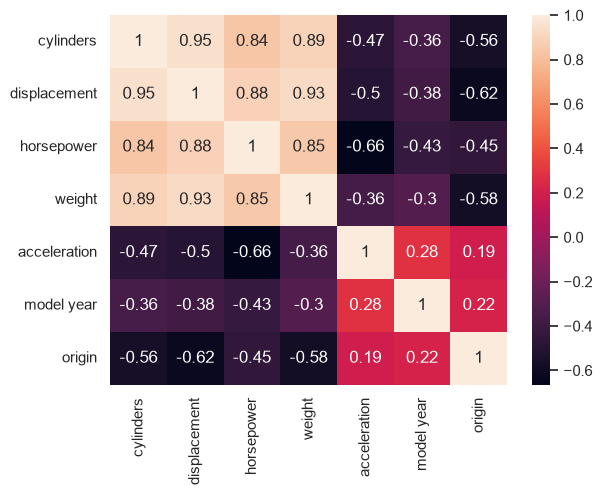

In [ ]:
correlation = X_train.corr(numeric_only=True)
sns.heatmap(correlation, annot=True, cbar=True)
plt.show()

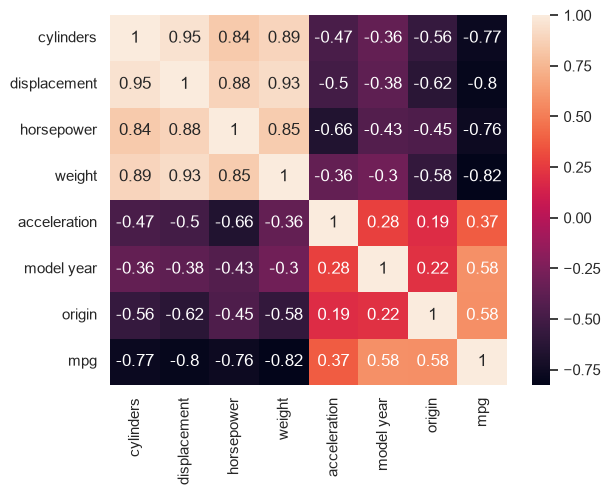

In [ ]:
train_comb = pd.concat([X_train, y_train], axis=1)
corr = train_comb.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cbar=True)
plt.show()